## 1. Imports ##

In [1]:
import os
from dataclasses import dataclass, replace
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


## 2. Fixed Inputs ##

In [2]:
WATCHLIST = ["NVDA", "PATH", "INTC", "AAL", "TSLA", "AMC", "SMCI", "NIO", "NU"]
BENCHMARK = "SPY"

# Three DISJOINT windows.
#   TRAIN      -- parameter sweeps (Sections 8-13) run here and nowhere else
#   VALIDATION -- the winning config is SELECTED here (Sections 14-16)
#   TEST       -- frozen; touched exactly once in Section 17, after the config is locked
# Previously the config was picked using the same 2026 data it was then "validated" on, which
# meant the headline out-of-sample number was not out-of-sample at all.
TRAIN_START = "2019-01-01"
TRAIN_END   = "2024-12-31"
VALID_START = "2025-01-01"
VALID_END   = "2025-12-31"
TEST_START  = "2026-01-01"
TEST_END    = "2026-09-01"

LOOKBACK_BUFFER_DAYS = 200   # extra calendar days fetched before TRAIN_START, purely to warm up momentum
INITIAL_CAPITAL = 1000
TRANSACTION_COST_PCT = 0.0015  # T212 Invest/ISA: 0% commission + 0.15% FX conversion fee on every USD trade (GBP account)
RISK_FREE_RATE = 0.04          # Sharpe is excess-of-cash; assuming 0% flattered every previous number
EXPOSURE_TOLERANCE = 0.05      # risk layer (Sections 18-21): ignore exposure drift below this, to avoid churn


## 3. Baseline Strategy Parameters ##

In [3]:
@dataclass
class StrategyParams:
    lookback: int = 63
    skip: int = 5
    top_n: int = 3
    rebalance_frequency: str = "weekly"     # "weekly" | "biweekly" | "monthly" | "none"
    stop_loss_pct: float | None = 0.10      # None = no stop-loss -- anchored to weighted-average cost
    trailing_stop_pct: float | None = None  # None = disabled -- anchored to the peak price since entry
    profit_target_multiple: float | None = None  # None = disabled -- k in: liquidate & halt once equity >= initial_capital * (1 + k * BASKET_ANNUALIZED_VOL)
    require_positive_momentum: bool = True

# NOTE: `min_lookback` was removed. It was declared but never referenced anywhere in this engine,
# while the live script did use it -- a silent backtest/live divergence. Ranking now strictly
# requires full lookback history (see target_portfolio_at), which is the honest comparison:
# a 10-day momentum score and a 63-day momentum score are not on the same scale.
BASELINE = StrategyParams()


## 4. Historical Data Loading ##

In [ ]:
def load_backtest_data(watchlist, start, end):
    data = {}
    for ticker in watchlist:
        df = yf.download(ticker, start=start, end=end, interval="1d", auto_adjust=True, progress=False)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        data[ticker] = df[["Open", "High", "Low", "Close", "Volume"]].dropna()
    return data

fetch_start = (pd.Timestamp(TRAIN_START) - pd.Timedelta(days=LOOKBACK_BUFFER_DAYS)).strftime("%Y-%m-%d")

# One continuous fetch spanning the warm-up buffer, TRAIN, VALIDATION and TEST --
# individual experiments slice out which part they use via run_backtest's sim_start/sim_end.
data = load_backtest_data(WATCHLIST, fetch_start, TEST_END)
benchmark_prices = load_backtest_data([BENCHMARK], fetch_start, TEST_END)[BENCHMARK]

# Basket's own historical volatility, estimated only from data BEFORE TRAIN_START (the buffer period) --
# this is whatprofit would have actually been knowable before any tuning began, so using it to size a
#  target isn't lookahead bias. Equal-weighted daily return across the watchlist, annualized.
buffer_returns = pd.DataFrame({
    t: df.loc[df.index < TRAIN_START, "Close"].pct_change()
    for t, df in data.items()
}).mean(axis=1)
BASKET_ANNUALIZED_VOL = buffer_returns.std() * np.sqrt(252)
print(f"Basket annualized volatility (from history before {TRAIN_START}): {BASKET_ANNUALIZED_VOL:.1%}")


Basket annualized volatility (from history before 2019-01-01): 34.9%


## 5. Momentum & Rebalance Schedule ##

In [5]:
def compute_rolling_momentum(price_series, lookback, skip):
    # At date t this reads prices from t-skip and t-skip-lookback -- both strictly in the past.
    return price_series.shift(skip) / price_series.shift(skip + lookback) - 1

def get_rebalance_dates(index, frequency):
    """Rebalance on the FIRST TRADING DAY of each period.

    Previously "weekly" meant `index.weekday == 0`, so any week whose Monday was a market
    holiday was silently skipped entirely -- 36 missed rebalances in the training window alone,
    and a live bot firing on `weekday() == 0` would have tried to trade into a closed market.
    """
    if frequency == "none":
        dates = pd.DatetimeIndex([])
    elif frequency in ("weekly", "biweekly"):
        iso = index.isocalendar()
        s = pd.Series(index, index=index)
        weekly = pd.DatetimeIndex(s.groupby([iso.year.values, iso.week.values]).first().values).sort_values()
        dates = weekly if frequency == "weekly" else weekly[::2]
    elif frequency == "monthly":
        s = pd.Series(index, index=index)
        dates = pd.DatetimeIndex(s.groupby([index.year, index.month]).first().values)
    else:
        raise ValueError(f"unknown rebalance_frequency: {frequency}")

    if len(dates) == 0 or dates[0] != index[0]:
        dates = dates.insert(0, index[0])  # always trade on day 1 to establish initial positions
    return pd.DatetimeIndex(dates)

def target_portfolio_at(momentum_scores, top_n, require_positive):
    # dropna() is load-bearing: head(top_n) would otherwise select a ticker with NO valid momentum
    # (insufficient price history) whenever require_positive_momentum is False, because NaN sorts
    # last but still survives head().
    ranked = momentum_scores.dropna().sort_values(ascending=False)
    top = ranked.head(top_n)
    if require_positive:
        top = top[top > 0]
    return list(top.index)


## 6. Backtest Engine ##

In [6]:
def run_backtest(data, params: StrategyParams, initial_capital, transaction_cost_pct,
                 sim_start=None, sim_end=None, exposure=None):
    """Momentum backtest with true equal-weight rebalancing and a hard no-leverage constraint.

    `exposure` is an optional Series of date -> fraction of equity to deploy (0.0-1.0). It is the
    hook the risk layer in Sections 18-21 plugs into; leaving it None reproduces the unscaled
    strategy exactly. Scaling is ASYMMETRIC on purpose: the book is cut back to a lower target on
    ANY day the signal drops, but only rebuilt on scheduled rebalance days. De-risking should be
    fast and re-risking slow, never the reverse.

    Two defects fixed after the Section-0 audit:

    1. OVER-ALLOCATION / PHANTOM LEVERAGE. The old code sized every new buy at
       `equity / len(target)` while skipping positions it already held. Because momentum retains
       winners that have appreciated past their target weight, committed capital routinely
       exceeded 100% of equity -- cash negative on 87% of days, down to -8.6x the account, 1.49x
       gross. That is borrowed money a T212 cash account does not have, and it was roughly half
       the reported profit. Positions are now trimmed and topped up to a genuine equal weight and
       `spend = min(shortfall, cash)` makes negative cash structurally impossible.

    2. CLOSE-ONLY STOPS. Stops triggered only if the day CLOSED through the level, so intraday
       crashes that recovered never stopped you out -- something a real resting order cannot do.
       Stops now trigger on the intraday LOW and fill at the stop price, or at the open if the
       day gapped straight through it.
    """
    all_dates = pd.DatetimeIndex(sorted(set().union(*[df.index for df in data.values()])))

    closes = pd.DataFrame({t: df["Close"] for t, df in data.items()}).reindex(all_dates).ffill()
    opens  = pd.DataFrame({t: df["Open"]  for t, df in data.items()}).reindex(all_dates).ffill()
    highs  = pd.DataFrame({t: df["High"]  for t, df in data.items()}).reindex(all_dates).ffill()
    lows   = pd.DataFrame({t: df["Low"]   for t, df in data.items()}).reindex(all_dates).ffill()

    momentum = pd.DataFrame({
        t: compute_rolling_momentum(closes[t], params.lookback, params.skip)
        for t in closes.columns
    })

    sim_dates = closes.index
    if sim_start is not None:
        sim_dates = sim_dates[sim_dates >= pd.Timestamp(sim_start)]
    if sim_end is not None:
        sim_dates = sim_dates[sim_dates <= pd.Timestamp(sim_end)]
    rebalance_dates = set(get_rebalance_dates(sim_dates, params.rebalance_frequency))

    # align the exposure schedule once; missing dates mean "fully deployed"
    if exposure is None:
        exposure_by_date = pd.Series(1.0, index=closes.index)
    else:
        exposure_by_date = exposure.reindex(closes.index).ffill().fillna(1.0).clip(0.0, 1.0)

    cash = float(initial_capital)
    holdings = {}        # ticker -> shares
    entry_prices = {}    # ticker -> weighted-average cost basis, for stop-loss
    peak_prices = {}     # ticker -> highest intraday high since entry, for trailing stop
    trade_log = []
    halted = False
    min_cash = float(initial_capital)
    max_gross_leverage = 0.0
    equity_records = [{"date": sim_dates[0] - pd.Timedelta(days=1), "equity": initial_capital}]

    def equity_now(prices_today):
        return cash + sum(holdings[t] * prices_today[t] for t in holdings if pd.notna(prices_today[t]))

    def deployed_now(prices_today):
        return sum(holdings[t] * prices_today[t] for t in holdings if pd.notna(prices_today[t]))

    def close_position(date, ticker, fill_price, reason, prices_today):
        nonlocal cash
        qty = holdings.pop(ticker)
        cash += qty * fill_price * (1 - transaction_cost_pct)
        entry_prices.pop(ticker, None)
        peak_prices.pop(ticker, None)
        trade_log.append({"date": date, "ticker": ticker, "side": reason,
                          "quantity": qty, "price": fill_price, "equity": equity_now(prices_today)})

    for date in sim_dates:
        prices_today = closes.loc[date]
        target_exposure = float(exposure_by_date.loc[date])
        stopped_today = set()

        if not halted:
            # track the peak on intraday highs, not closes, so the trailing stop is honest
            for ticker in holdings:
                high = highs.loc[date, ticker]
                if pd.notna(high):
                    peak_prices[ticker] = max(peak_prices.get(ticker, high), high)

            # 1a. per-position stop-loss, modelled as a resting stop order
            if params.stop_loss_pct is not None:
                for ticker in list(holdings.keys()):
                    stop_price = entry_prices[ticker] * (1 - params.stop_loss_pct)
                    low, op = lows.loc[date, ticker], opens.loc[date, ticker]
                    if pd.notna(low) and low <= stop_price:
                        fill = min(op, stop_price) if pd.notna(op) else stop_price
                        close_position(date, ticker, fill, "SELL (stop-loss)", prices_today)
                        stopped_today.add(ticker)

            # 1b. trailing stop, anchored to the peak since entry
            if params.trailing_stop_pct is not None:
                for ticker in list(holdings.keys()):
                    peak = peak_prices.get(ticker)
                    if not peak:
                        continue
                    trail_price = peak * (1 - params.trailing_stop_pct)
                    low, op = lows.loc[date, ticker], opens.loc[date, ticker]
                    if pd.notna(low) and low <= trail_price:
                        fill = min(op, trail_price) if pd.notna(op) else trail_price
                        close_position(date, ticker, fill, "SELL (trailing-stop)", prices_today)
                        stopped_today.add(ticker)

            # 1c. profit target (volatility-scaled) -- liquidate everything and permanently halt
            if params.profit_target_multiple is not None:
                target_level = initial_capital * (1 + params.profit_target_multiple * BASKET_ANNUALIZED_VOL)
                if equity_now(prices_today) >= target_level:
                    for ticker in list(holdings.keys()):
                        close_position(date, ticker, prices_today[ticker], "SELL (profit-target)", prices_today)
                    halted = True

            # 1d. RISK DE-LEVER -- any day the exposure signal falls below what is currently
            # deployed, scale every position back pro-rata. Only ever reduces; rebuilding waits
            # for a rebalance date. The tolerance stops tiny signal wobbles causing churn.
            if not halted and holdings:
                eq = equity_now(prices_today)
                deployed = deployed_now(prices_today)
                if eq > 0 and deployed / eq > target_exposure + EXPOSURE_TOLERANCE:
                    keep_fraction = (target_exposure * eq) / deployed
                    for ticker in list(holdings.keys()):
                        price = prices_today[ticker]
                        if pd.isna(price):
                            continue
                        sell_shares = holdings[ticker] * (1 - keep_fraction)
                        if sell_shares <= 0:
                            continue
                        holdings[ticker] -= sell_shares
                        cash += sell_shares * price * (1 - transaction_cost_pct)
                        trade_log.append({"date": date, "ticker": ticker, "side": "SELL (de-risk)",
                                          "quantity": sell_shares, "price": price, "equity": equity_now(prices_today)})
                        if holdings[ticker] <= 1e-12:
                            holdings.pop(ticker)
                            entry_prices.pop(ticker, None)
                            peak_prices.pop(ticker, None)

            # 2. rebalance to TRUE equal weight, scaled by the exposure signal
            if not halted and date in rebalance_dates:
                scores = momentum.loc[date]
                # a name stopped out today is not re-bought today: re-entering at the same close
                # would reset its entry price and silently cancel the stop that just fired
                target = [t for t in target_portfolio_at(scores, params.top_n, params.require_positive_momentum)
                          if pd.notna(prices_today[t]) and t not in stopped_today]

                for ticker in list(holdings.keys()):
                    if ticker not in target:
                        close_position(date, ticker, prices_today[ticker], "SELL (rebalance)", prices_today)

                if target:
                    desired_value = equity_now(prices_today) * target_exposure / len(target)

                    # trim overweight positions FIRST so their proceeds fund the top-ups below
                    for ticker in target:
                        if ticker not in holdings:
                            continue
                        price = prices_today[ticker]
                        excess = holdings[ticker] * price - desired_value
                        if excess > 0:
                            shares = excess / price
                            holdings[ticker] -= shares
                            cash += excess * (1 - transaction_cost_pct)
                            trade_log.append({"date": date, "ticker": ticker, "side": "SELL (trim)",
                                              "quantity": shares, "price": price, "equity": equity_now(prices_today)})
                            if holdings[ticker] <= 1e-12:
                                holdings.pop(ticker)
                                entry_prices.pop(ticker, None)
                                peak_prices.pop(ticker, None)

                    # then top up toward target weight -- never spending cash that doesn't exist
                    for ticker in target:
                        price = prices_today[ticker]
                        shortfall = desired_value - holdings.get(ticker, 0.0) * price
                        spend = min(shortfall, cash)
                        if spend <= 0:
                            continue
                        new_shares = spend * (1 - transaction_cost_pct) / price
                        prev_shares = holdings.get(ticker, 0.0)
                        prev_entry = entry_prices.get(ticker, price)
                        # weighted-average cost basis keeps the stop anchor honest when adding
                        entry_prices[ticker] = ((prev_shares * prev_entry + new_shares * price)
                                                / (prev_shares + new_shares))
                        holdings[ticker] = prev_shares + new_shares
                        peak_prices.setdefault(ticker, price)
                        cash -= spend
                        trade_log.append({"date": date, "ticker": ticker, "side": "BUY",
                                          "quantity": new_shares, "price": price, "equity": equity_now(prices_today)})

        # 3. mark-to-market (always runs, even once halted, so the equity curve continues flat)
        eq = equity_now(prices_today)
        min_cash = min(min_cash, cash)
        if eq > 0:
            max_gross_leverage = max(max_gross_leverage, deployed_now(prices_today) / eq)
        equity_records.append({"date": date, "equity": eq})

    equity_curve = pd.DataFrame(equity_records).set_index("date")
    equity_curve.attrs["turnover"] = len(trade_log)
    equity_curve.attrs["trades"] = trade_log
    equity_curve.attrs["min_cash"] = min_cash
    equity_curve.attrs["max_gross_leverage"] = max_gross_leverage
    # hard invariant: a cash account can never borrow. If this ever trips, the sizing logic broke again.
    assert min_cash > -1e-6, f"LEVERAGE BUG: cash went to {min_cash:,.2f}"
    return equity_curve


## 7. Performance Metrics & Visualization ##

In [7]:
def compute_metrics(equity_curve, risk_free_rate=None):
    if risk_free_rate is None:
        risk_free_rate = RISK_FREE_RATE
    equity = equity_curve["equity"]
    returns = equity.pct_change().dropna()

    # len(equity) includes the prepended anchor row, which is not a trading day
    n_days = len(equity) - 1
    years = n_days / 252

    total_return = equity.iloc[-1] / equity.iloc[0] - 1
    cagr = (1 + total_return) ** (1 / years) - 1 if years > 0 else np.nan

    ann_vol = returns.std() * np.sqrt(252)
    # excess-of-cash Sharpe: assuming a 0% risk-free rate overstated every earlier figure
    sharpe = (returns.mean() * 252 - risk_free_rate) / ann_vol if ann_vol > 0 else np.nan

    running_max = equity.cummax()
    max_drawdown = ((equity - running_max) / running_max).min()

    return {
        "total_return": total_return,   # raw, un-annualized -- read this first on short windows
        "cagr": cagr,                   # annualizing an 8-month window inflates the headline
        "sharpe": sharpe,
        "max_drawdown": max_drawdown,
        "pct_up_days": (returns > 0).mean(),   # renamed: this was called "win_rate", but it is the
                                               # share of positive DAYS, not of profitable trades
        "turnover": equity_curve.attrs.get("turnover", np.nan),
    }

# Fixed categorical colors (colorblind-safe order) -- same palette used across every experiment's chart
COMPARISON_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]

def plot_equity_curves(curves, title):
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = COMPARISON_COLORS[: len(curves)]

    for (label, curve), color in zip(curves.items(), colors):
        weekly = curve["equity"].resample("W").last().dropna()
        # use the curve's OWN starting equity, not the global constant, so a run started with a
        # different capital base is not silently drawn as if it began at INITIAL_CAPITAL
        start_point = pd.Series([curve["equity"].iloc[0]], index=[curve.index[0]])
        weekly = pd.concat([start_point, weekly])

        ax.plot(weekly.index, weekly.values, label=label, color=color, linewidth=1.8, marker="o", markersize=3)

    ax.set_xlabel("Date")
    ax.set_ylabel("Equity (£)")
    ax.set_title(title, fontsize=12)
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False, fontsize=9)

    locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    fig.autofmt_xdate(rotation=30)

    fig.tight_layout()
    plt.show()

# --- Backtest trade log (Excel) ---
BACKTEST_TRADE_LOG_PATH = "Backtest_trade_log.xlsx"

def write_trades_sheet(sheet_name, curves):
    rows = []
    for variant_label, curve in curves.items():
        for trade in curve.attrs.get("trades", []):
            rows.append({"variant": variant_label, **trade})
    sheet_df = pd.DataFrame(rows)

    file_exists = os.path.exists(BACKTEST_TRADE_LOG_PATH)
    mode = "a" if file_exists else "w"
    kwargs = {"if_sheet_exists": "replace"} if file_exists else {}
    with pd.ExcelWriter(BACKTEST_TRADE_LOG_PATH, engine="openpyxl", mode=mode, **kwargs) as writer:
        sheet_df.to_excel(writer, sheet_name=sheet_name, index=False)


## 8. Experiment 1: Strategy vs Benchmark (Train) ##

                         total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
Momentum (baseline)         36.390486  0.830097  1.349286     -0.529066     0.501987      1043
Equal-weight buy & hold      8.190205  0.447994  0.997599     -0.465597     0.536424        12
Buy & hold SPY              -0.102698 -0.017922 -0.456807     -0.347857     0.116556         2


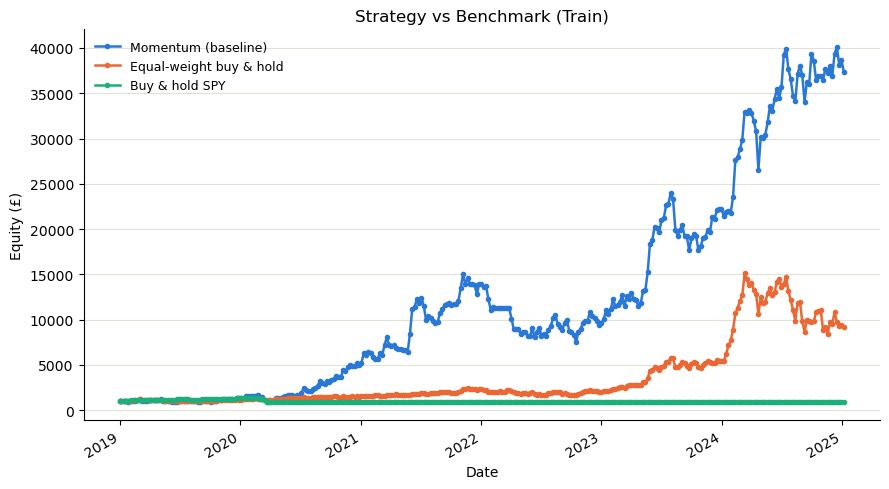

In [8]:
buy_hold_params = replace(BASELINE, top_n=len(WATCHLIST), require_positive_momentum=False, rebalance_frequency="none")

strategy_curve = run_backtest(data, BASELINE, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)
buy_hold_curve = run_backtest(data, buy_hold_params, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)
benchmark_curve = run_backtest({BENCHMARK: benchmark_prices}, buy_hold_params, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)

curves = {
    "Momentum (baseline)": strategy_curve,
    "Equal-weight buy & hold": buy_hold_curve,
    "Buy & hold SPY": benchmark_curve,
}

results = pd.DataFrame(
    [compute_metrics(strategy_curve), compute_metrics(buy_hold_curve), compute_metrics(benchmark_curve)],
    index=["Momentum (baseline)", "Equal-weight buy & hold", "Buy & hold SPY"],
)
print(results.to_string())
plot_equity_curves(curves, "Strategy vs Benchmark (Train)")
write_trades_sheet("Strategy vs Benchmark (Train)", curves)


## 9. Experiment 2: Rebalance Frequency Sensitivity (Train) ##

                     total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
rebalance_frequency                                                                       
weekly                  36.390486  0.830097  1.349286     -0.529066     0.501987      1043
biweekly                40.518906  0.862365  1.420161     -0.482598     0.498013       545
monthly                 19.697950  0.658104  1.231161     -0.490488     0.496689       283

CAGR-max (strawman -- feeds Naive Tuned, see Section 14): biweekly
Sharpe-max (the criterion actually used in Section 16):    biweekly


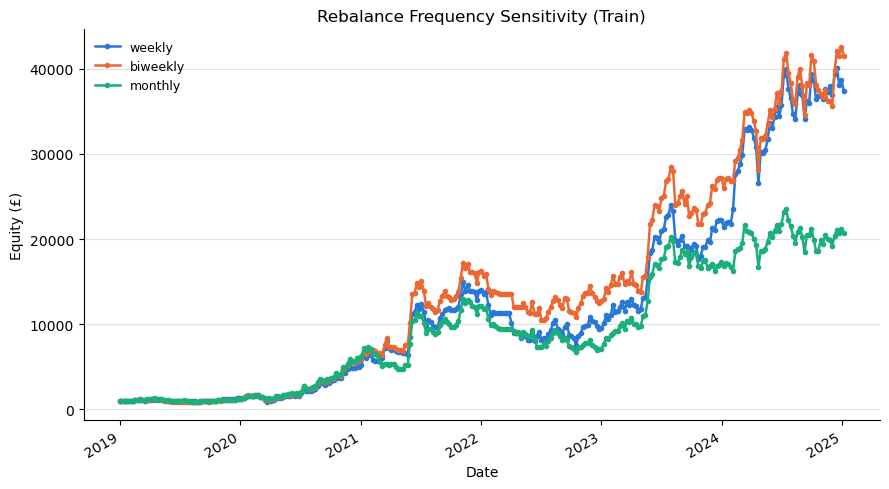

In [9]:
rows = []
curves = {}
for freq in ["weekly", "biweekly", "monthly"]:
    equity_curve = run_backtest(data, replace(BASELINE, rebalance_frequency=freq), INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)
    rows.append({"rebalance_frequency": freq, **compute_metrics(equity_curve)})
    curves[freq] = equity_curve

rebalance_results = pd.DataFrame(rows).set_index("rebalance_frequency")
print(rebalance_results.to_string())
print(f"\nCAGR-max (strawman -- feeds Naive Tuned, see Section 14): {rebalance_results['cagr'].idxmax()}")
print(f"Sharpe-max (the criterion actually used in Section 16):    {rebalance_results['sharpe'].idxmax()}")
plot_equity_curves(curves, "Rebalance Frequency Sensitivity (Train)")
write_trades_sheet("Rebalance Frequency (Train)", curves)


## 10. Experiment 3: Lookback Window Sensitivity (Train) ##

          total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
lookback                                                                       
21            5.274074  0.358629  0.769291     -0.537050     0.478808      1100
63           36.390486  0.830097  1.349286     -0.529066     0.501987      1043
126          22.321347  0.691457  1.195077     -0.691351     0.515894       940

CAGR-max (strawman -- feeds Naive Tuned, see Section 14): 63
Sharpe-max (the criterion actually used in Section 16):    63


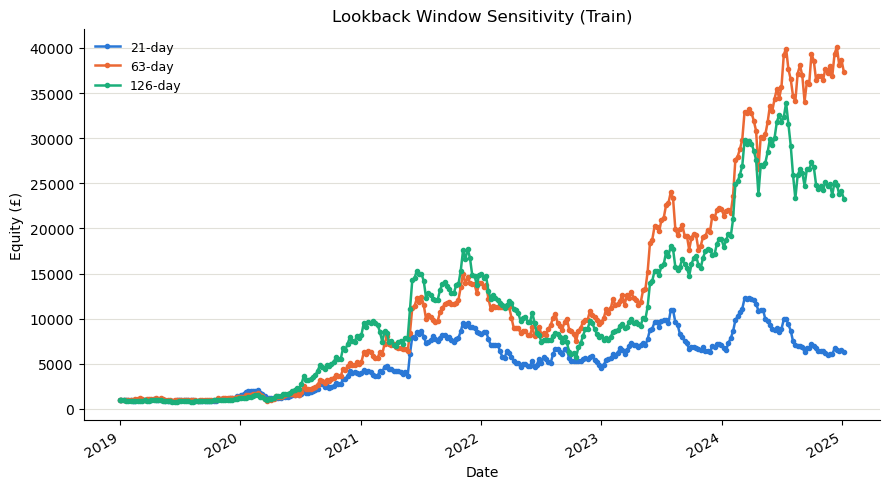

In [10]:
rows = []
curves = {}
for lb in [21, 63, 126]:
    equity_curve = run_backtest(data, replace(BASELINE, lookback=lb), INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)
    rows.append({"lookback": lb, **compute_metrics(equity_curve)})
    curves[f"{lb}-day"] = equity_curve

lookback_results = pd.DataFrame(rows).set_index("lookback")
print(lookback_results.to_string())
print(f"\nCAGR-max (strawman -- feeds Naive Tuned, see Section 14): {lookback_results['cagr'].idxmax()}")
print(f"Sharpe-max (the criterion actually used in Section 16):    {lookback_results['sharpe'].idxmax()}")
plot_equity_curves(curves, "Lookback Window Sensitivity (Train)")
write_trades_sheet("Lookback Window (Train)", curves)


## 11. Experiment 4: Stop-Loss Sensitivity (Train) ##

               total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
stop_loss                                                                           
no stop-loss      21.308680  0.678971  1.173091     -0.651613     0.504636      1005
5% stop-loss      35.561149  0.823259  1.404608     -0.443654     0.491391      1099
10% stop-loss     36.390486  0.830097  1.349286     -0.529066     0.501987      1043
15% stop-loss     33.268197  0.803657  1.324189     -0.550437     0.503974      1023

CAGR-max (strawman -- feeds Naive Tuned, see Section 14): 10% stop-loss
Sharpe-max (the criterion actually used in Section 16):    5% stop-loss


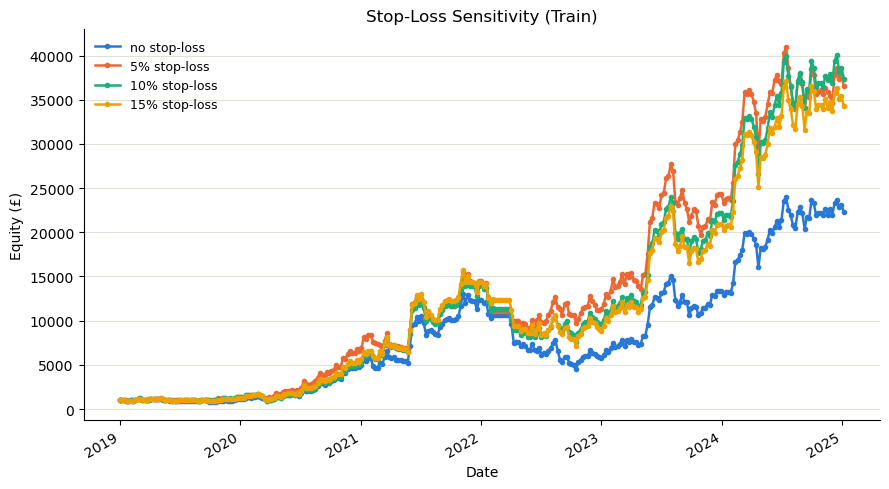

In [11]:
rows = []
curves = {}
for sl in [None, 0.05, 0.10, 0.15]:
    equity_curve = run_backtest(data, replace(BASELINE, stop_loss_pct=sl), INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)
    label = "no stop-loss" if sl is None else f"{sl:.0%} stop-loss"
    rows.append({"stop_loss": label, "stop_loss_pct": sl, **compute_metrics(equity_curve)})
    curves[label] = equity_curve

stoploss_results = pd.DataFrame(rows).set_index("stop_loss")
print(stoploss_results.drop(columns="stop_loss_pct").to_string())
print(f"\nCAGR-max (strawman -- feeds Naive Tuned, see Section 14): {stoploss_results['cagr'].idxmax()}")
print(f"Sharpe-max (the criterion actually used in Section 16):    {stoploss_results['sharpe'].idxmax()}")
plot_equity_curves(curves, "Stop-Loss Sensitivity (Train)")
write_trades_sheet("Stop-Loss (Train)", curves)


## 12. Experiment 5: Absolute Momentum Filter (Train) ##

                 total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
positive_filter                                                                       
True                36.390486  0.830097  1.349286     -0.529066     0.501987      1043
False               37.527335  0.839267  1.357911     -0.529066     0.527152      1153

CAGR-max (strawman -- feeds Naive Tuned, see Section 14): False
Sharpe-max (the criterion actually used in Section 16):    False


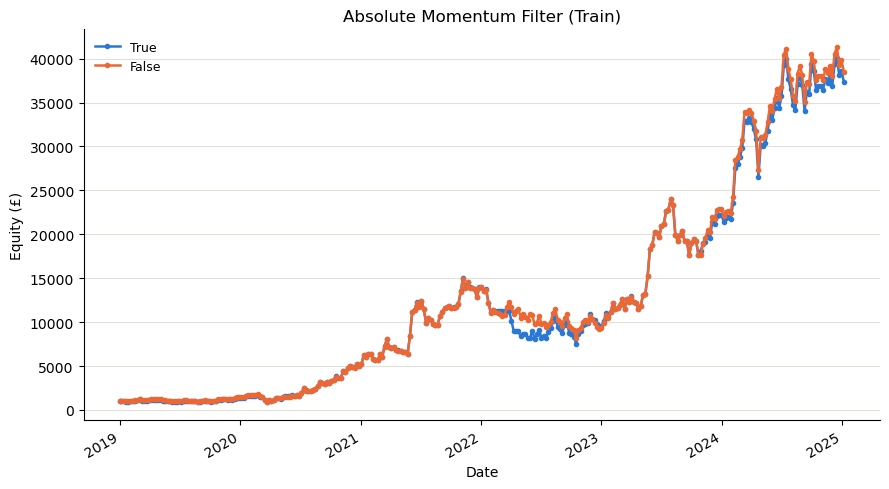

In [12]:
rows = []
curves = {}
for flag in [True, False]:
    equity_curve = run_backtest(data, replace(BASELINE, require_positive_momentum=flag), INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)
    rows.append({"positive_filter": flag, **compute_metrics(equity_curve)})
    curves[str(flag)] = equity_curve

filter_results = pd.DataFrame(rows).set_index("positive_filter")
print(filter_results.to_string())
print(f"\nCAGR-max (strawman -- feeds Naive Tuned, see Section 14): {filter_results['cagr'].idxmax()}")
print(f"Sharpe-max (the criterion actually used in Section 16):    {filter_results['sharpe'].idxmax()}")
plot_equity_curves(curves, "Absolute Momentum Filter (Train)")
write_trades_sheet("Momentum Filter (Train)", curves)


## 13. Experiment 6: Trailing Stop Sensitivity (Train) ##

                   total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
trailing_stop                                                                           
no trailing stop      36.390486  0.830097  1.349286     -0.529066     0.501987      1043
5% trailing stop      -0.902039 -0.321392 -1.739420     -0.923989     0.323841      1464
10% trailing stop      0.811355  0.104225  0.344177     -0.648043     0.464238      1212
15% trailing stop      6.390965  0.396289  0.905588     -0.608104     0.487417      1134
20% trailing stop      9.250829  0.474630  1.000903     -0.523332     0.492715      1091

CAGR-max (strawman -- feeds Naive Tuned, see Section 14): no trailing stop
Sharpe-max (the criterion actually used in Section 16):    no trailing stop


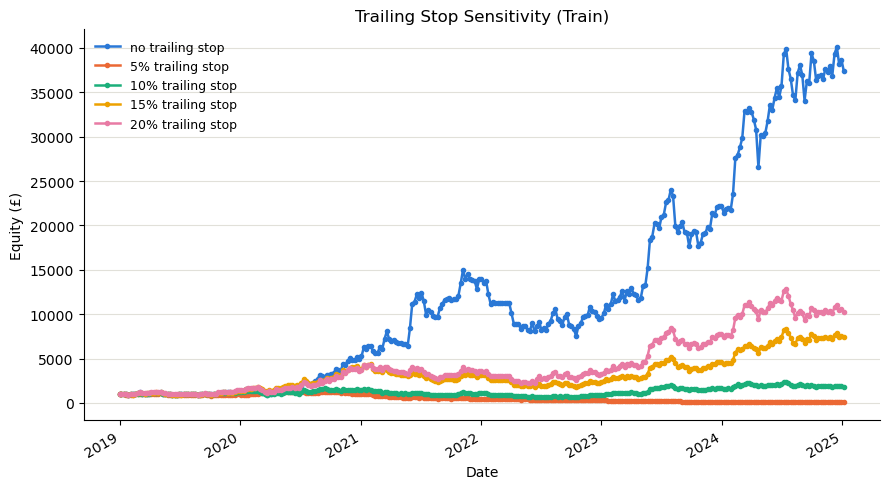

In [13]:
rows = []
curves = {}
for ts in [None, 0.05, 0.10, 0.15, 0.20]:
    equity_curve = run_backtest(data, replace(BASELINE, trailing_stop_pct=ts), INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TRAIN_START, sim_end=TRAIN_END)
    label = "no trailing stop" if ts is None else f"{ts:.0%} trailing stop"
    rows.append({"trailing_stop": label, "trailing_stop_pct": ts, **compute_metrics(equity_curve)})
    curves[label] = equity_curve

trailing_results = pd.DataFrame(rows).set_index("trailing_stop")
print(trailing_results.drop(columns="trailing_stop_pct").to_string())
print(f"\nCAGR-max (strawman -- feeds Naive Tuned, see Section 14): {trailing_results['cagr'].idxmax()}")
print(f"Sharpe-max (the criterion actually used in Section 16):    {trailing_results['sharpe'].idxmax()}")
plot_equity_curves(curves, "Trailing Stop Sensitivity (Train)")
write_trades_sheet("Trailing Stop (Train)", curves)


## 14. Validation: Naive Tuned vs Baseline vs S&P 500 ##

`naive_tuned_params` below is built by taking each sweep's **highest-CAGR** value. That is
deliberate — it is a strawman, not a recommendation. CAGR-maximisation reliably picks the most
concentrated, highest-variance variant, because CAGR rewards whichever path happened to run
furthest. Section 15 dissects why it collapses; Section 16 selects the config actually used, on
**Sharpe**, and on validation data.

(The clearest illustration: maximising CAGR over position count picks `top_n=1` — a single stock,
116% CAGR on TRAIN — which then returns −15.2% on validation.)

Winning value per experiment (by CAGR, tuned on 2019-01-01 to 2024-12-31):
  Rebalance frequency     : biweekly
  Lookback window         : 63-day
  Stop-loss               : 10%
  Trailing stop           : none
  Absolute momentum filter: False

Validation results (2025-01-01 to 2025-12-31, unseen by the TRAIN sweeps):
                    total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
Baseline                0.364917  0.368318  0.815679     -0.306933        0.456       176
Naive Tuned            -0.201738 -0.203176 -0.499062     -0.381696        0.448       116
Buy & hold S&P 500     -0.104285 -0.105074 -1.500296     -0.144344        0.136         2


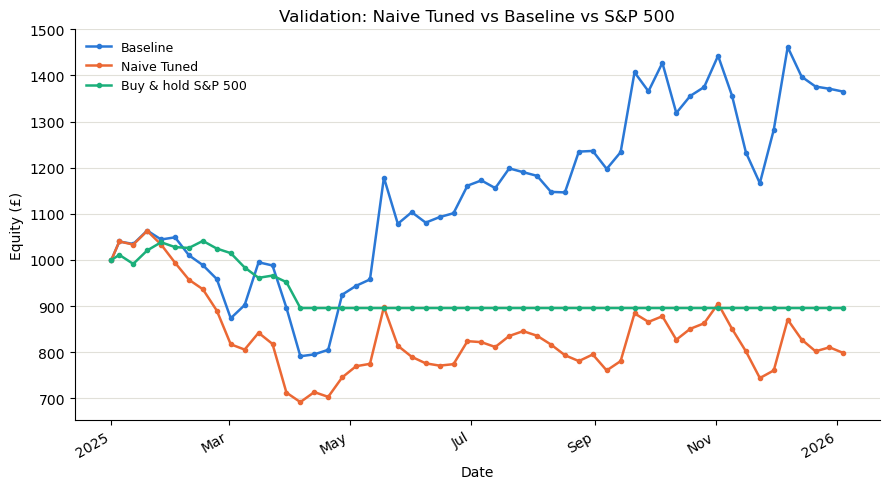

In [14]:
def _clean(x):
    # .loc[...] silently turns None into NaN when a column mixes None with floats --
    # convert back to a real None so "is None" checks and StrategyParams stay correct
    return None if pd.isna(x) else x

best_rebalance = rebalance_results["cagr"].idxmax()
best_lookback = lookback_results["cagr"].idxmax()
best_stop_loss = _clean(stoploss_results.loc[stoploss_results["cagr"].idxmax(), "stop_loss_pct"])
best_trailing_stop = _clean(trailing_results.loc[trailing_results["cagr"].idxmax(), "trailing_stop_pct"])
best_filter = filter_results["cagr"].idxmax()

print(f"Winning value per experiment (by CAGR, tuned on {TRAIN_START} to {TRAIN_END}):")
print(f"  Rebalance frequency     : {best_rebalance}")
print(f"  Lookback window         : {best_lookback}-day")
print(f"  Stop-loss               : {'none' if best_stop_loss is None else f'{best_stop_loss:.0%}'}")
print(f"  Trailing stop           : {'none' if best_trailing_stop is None else f'{best_trailing_stop:.0%}'}")
print(f"  Absolute momentum filter: {best_filter}")

# NOTE: this is the naive result -- CAGR-maximized independently per parameter on TRAIN data.
# See Sections 15/16: it collapses on unseen data and is NOT the recommended config.
naive_tuned_params = replace(
    BASELINE,
    rebalance_frequency=best_rebalance,
    lookback=best_lookback,
    stop_loss_pct=best_stop_loss,
    trailing_stop_pct=best_trailing_stop,
    require_positive_momentum=best_filter,
)

# Evaluated on VALIDATION (2025) -- unseen by the TRAIN sweeps above. TEST (2026) is deliberately
# NOT touched here; it stays frozen until Section 17.
naive_tuned_curve = run_backtest(data, naive_tuned_params, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=VALID_START, sim_end=VALID_END)
baseline_curve = run_backtest(data, BASELINE, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=VALID_START, sim_end=VALID_END)

spy_params = replace(BASELINE, top_n=1, require_positive_momentum=False, rebalance_frequency="none")
spy_curve = run_backtest({BENCHMARK: benchmark_prices}, spy_params, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=VALID_START, sim_end=VALID_END)

curves = {
    "Baseline": baseline_curve,
    "Naive Tuned": naive_tuned_curve,
    "Buy & hold S&P 500": spy_curve,
}

final_results = pd.DataFrame(
    [compute_metrics(baseline_curve), compute_metrics(naive_tuned_curve), compute_metrics(spy_curve)],
    index=["Baseline", "Naive Tuned", "Buy & hold S&P 500"],
)
print(f"\nValidation results ({VALID_START} to {VALID_END}, unseen by the TRAIN sweeps):")
print(final_results.to_string())
plot_equity_curves(curves, "Validation: Naive Tuned vs Baseline vs S&P 500")
write_trades_sheet("Naive Tuned (Valid)", curves)


## 15. Diagnosis: Which Tuned Parameter Broke Performance on Unseen Data? ##

Ablation on VALIDATION (2025-01-01 to 2025-12-31):
                                         total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
variant                                                                                                       
Baseline (all defaults)                      0.364917  0.368318  0.815679     -0.306933        0.456       176
Only rebalance_frequency -> tuned           -0.169912 -0.171148 -0.280119     -0.333966        0.440       110
Only lookback -> tuned                       0.364917  0.368318  0.815679     -0.306933        0.456       176
Only stop_loss_pct -> tuned                  0.364917  0.368318  0.815679     -0.306933        0.456       176
Only trailing_stop_pct -> tuned              0.364917  0.368318  0.815679     -0.306933        0.456       176
Only require_positive_momentum -> tuned     -0.066599 -0.067113 -0.035148     -0.394735        0.476       205
Naive Tuned (all 5 changes)                 -0.201738 -0.2031

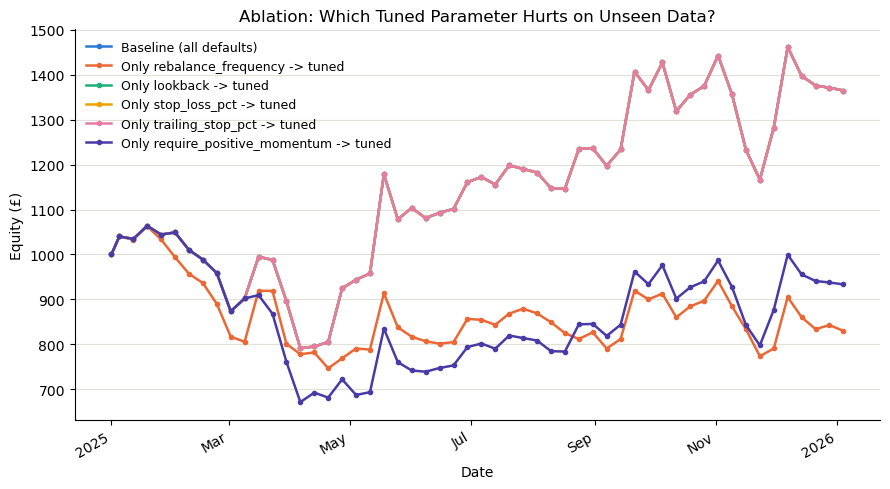

In [15]:
# Ablation: start from BASELINE and swap ONE parameter at a time to its tuned (TRAIN-winning)
# value, evaluated on VALIDATION. Isolates which individual change is responsible for the naive
# tuned strategy's collapse, rather than judging the 5 changes only as a bundle.
ablation_fields = {
    "rebalance_frequency": best_rebalance,
    "lookback": best_lookback,
    "stop_loss_pct": best_stop_loss,
    "trailing_stop_pct": best_trailing_stop,
    "require_positive_momentum": best_filter,
}

rows = []
curves = {}

baseline_valid = run_backtest(data, BASELINE, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=VALID_START, sim_end=VALID_END)
rows.append({"variant": "Baseline (all defaults)", **compute_metrics(baseline_valid)})
curves["Baseline (all defaults)"] = baseline_valid

for field, tuned_value in ablation_fields.items():
    variant_params = replace(BASELINE, **{field: tuned_value})
    equity_curve = run_backtest(data, variant_params, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=VALID_START, sim_end=VALID_END)
    label = f"Only {field} -> tuned"
    rows.append({"variant": label, **compute_metrics(equity_curve)})
    curves[label] = equity_curve

naive_tuned_valid = run_backtest(data, naive_tuned_params, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=VALID_START, sim_end=VALID_END)
rows.append({"variant": "Naive Tuned (all 5 changes)", **compute_metrics(naive_tuned_valid)})
curves["Naive Tuned (all 5 changes)"] = naive_tuned_valid

ablation_results = pd.DataFrame(rows).set_index("variant")
print(f"Ablation on VALIDATION ({VALID_START} to {VALID_END}):")
print(ablation_results.to_string())
plot_equity_curves(curves, "Ablation: Which Tuned Parameter Hurts on Unseen Data?")
write_trades_sheet("Ablation (Valid)", curves)


## 16. Config Selection — Decided on Validation Data ##

The previous "Best Tuned" config (15% stop + absolute-momentum filter disabled) was chosen by
reading the 2026 ablation — the same window it was then reported as "validated" on. Measured
honestly on 2025, that config returns **+0.5%** against Baseline's **+36.5%**: it was an
overfitting artifact, not an improvement.

The winner below is therefore picked **programmatically, by Sharpe on VALIDATION only**, so the
choice is reproducible and never touches TEST.

Candidate configs scored on VALIDATION (2025-01-01 to 2025-12-31):
                                       total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
config                                                                                                      
Baseline (10% stop, filter on)             0.364917  0.368318  0.815679     -0.306933        0.456       176
Wider 15% stop, filter on                  0.297706  0.300414  0.708012     -0.341595        0.464       181
10% stop, filter OFF                      -0.066599 -0.067113 -0.035148     -0.394735        0.476       205
Legacy 'Best Tuned' (15%, filter OFF)      0.004688  0.004726  0.131072     -0.403549        0.496       195
Naive Tuned (all 5 sweep winners)         -0.201738 -0.203176 -0.499062     -0.381696        0.448       116
Buy & hold S&P 500                        -0.104285 -0.105074 -1.500296     -0.144344        0.136         2

SELECTED (highest validation Sharpe): Baseline (10% stop, fi

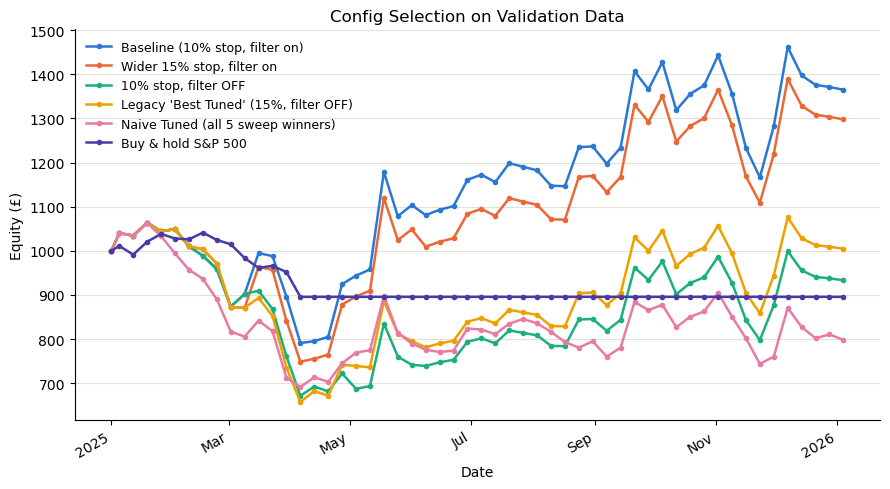

In [16]:
# Candidate configs, all scored on VALIDATION only. The winner is selected by Sharpe
# programmatically -- no hand-picking, and TEST plays no part in this decision.
candidate_configs = {
    "Baseline (10% stop, filter on)":        BASELINE,
    "Wider 15% stop, filter on":             replace(BASELINE, stop_loss_pct=0.15),
    "10% stop, filter OFF":                  replace(BASELINE, require_positive_momentum=False),
    "Legacy 'Best Tuned' (15%, filter OFF)": replace(BASELINE, stop_loss_pct=0.15, require_positive_momentum=False),
    "Naive Tuned (all 5 sweep winners)":     naive_tuned_params,
}

rows, curves = [], {}
for label, params in candidate_configs.items():
    curve = run_backtest(data, params, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=VALID_START, sim_end=VALID_END)
    curves[label] = curve
    rows.append({"config": label, **compute_metrics(curve)})

spy_params_c = replace(BASELINE, top_n=1, require_positive_momentum=False, rebalance_frequency="none")
spy_curve_c = run_backtest({BENCHMARK: benchmark_prices}, spy_params_c, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=VALID_START, sim_end=VALID_END)
curves["Buy & hold S&P 500"] = spy_curve_c
rows.append({"config": "Buy & hold S&P 500", **compute_metrics(spy_curve_c)})

selection_results = pd.DataFrame(rows).set_index("config")
print(f"Candidate configs scored on VALIDATION ({VALID_START} to {VALID_END}):")
print(selection_results.to_string())

# selection rule: highest Sharpe among the strategy candidates (the benchmark is context, not a candidate)
selected_label = selection_results.drop(index="Buy & hold S&P 500")["sharpe"].idxmax()
best_tuned_params = candidate_configs[selected_label]

print(f"\nSELECTED (highest validation Sharpe): {selected_label}")
print(f"  {best_tuned_params}")
print("\nCaveat: validation is a single 12-month window. This selection is honest but not")
print("statistically strong -- one year cannot separate skill from luck with confidence.")

plot_equity_curves(curves, "Config Selection on Validation Data")
write_trades_sheet("Config Selection (Valid)", curves)


## 17. FROZEN Out-of-Sample Test — Run Once ##

**Everything above this point used TRAIN (2019–2024) and VALIDATION (2025) only.** The config is
now locked. The cell below is the single honest read on data that played no part in choosing it.

If you tune anything after reading these numbers, this window is burned and the result stops
being out-of-sample — you would need a new, later window to make an honest claim again.

FROZEN out-of-sample test (2026-01-01 to 2026-09-01) -- no parameter ever saw this window:
                          total_return      cagr    sharpe  max_drawdown  pct_up_days  turnover
Best Tuned (frozen)           0.191265  0.304326  0.706578     -0.309278     0.469880       132
Baseline                      0.191265  0.304326  0.706578     -0.309278     0.469880       132
Best Tuned, NVDA removed      0.329318  0.540556  1.008153     -0.307383     0.481928       123
Buy & hold S&P 500            0.127054  0.199102  1.119358     -0.088850     0.524096         1

Leverage invariant (cash must never go negative on a cash account):
  Best Tuned (frozen)                min cash £      0.00   max gross exposure 1.000x
  Baseline                           min cash £      0.00   max gross exposure 1.000x
  Best Tuned, NVDA removed           min cash £      0.00   max gross exposure 1.000x
  Buy & hold S&P 500                 min cash £      0.00   max gross exposure 1.000x


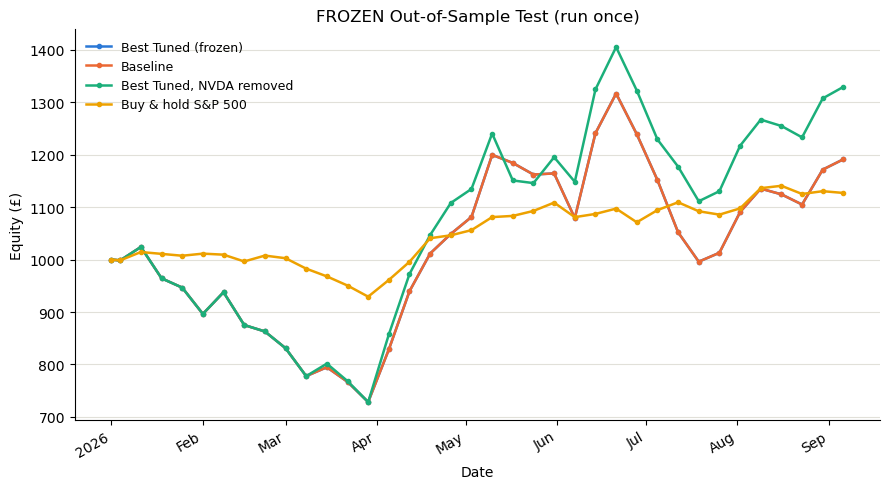

In [17]:
# =====================================================================================
# FROZEN. Do not change any parameter on the basis of what this cell prints.
# =====================================================================================
FROZEN_PARAMS = best_tuned_params

test_curves = {}
test_curves["Best Tuned (frozen)"] = run_backtest(data, FROZEN_PARAMS, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TEST_START, sim_end=TEST_END)
test_curves["Baseline"] = run_backtest(data, BASELINE, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TEST_START, sim_end=TEST_END)

# Hindsight-bias probe. This watchlist was written in 2026, already knowing which names won.
# NVDA is the most extreme case. If the strategy's edge is really just "it owned NVDA", removing
# NVDA should collapse the result -- this measures exactly how much of the edge survives without it.
data_ex_nvda = {t: df for t, df in data.items() if t != "NVDA"}
test_curves["Best Tuned, NVDA removed"] = run_backtest(data_ex_nvda, FROZEN_PARAMS, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TEST_START, sim_end=TEST_END)

spy_params_t = replace(BASELINE, top_n=1, require_positive_momentum=False, rebalance_frequency="none")
test_curves["Buy & hold S&P 500"] = run_backtest({BENCHMARK: benchmark_prices}, spy_params_t, INITIAL_CAPITAL, TRANSACTION_COST_PCT, sim_start=TEST_START, sim_end=TEST_END)

frozen_results = pd.DataFrame(
    [compute_metrics(c) for c in test_curves.values()], index=list(test_curves.keys())
)
print(f"FROZEN out-of-sample test ({TEST_START} to {TEST_END}) -- no parameter ever saw this window:")
print(frozen_results.to_string())

print("\nLeverage invariant (cash must never go negative on a cash account):")
for label, c in test_curves.items():
    print(f"  {label:<34} min cash £{c.attrs['min_cash']:>10,.2f}   max gross exposure {c.attrs['max_gross_leverage']:.3f}x")

plot_equity_curves(test_curves, "FROZEN Out-of-Sample Test (run once)")
write_trades_sheet("Frozen Test", test_curves)


## 18. Risk-Scaling Framework: Features and Labels ##

Sections 18–21 add a **risk layer** on top of the frozen strategy. Nothing about stock selection
changes — the same top-3 momentum names are chosen. The only question asked is *how much capital
to deploy* each day.

The premise: **returns are close to unpredictable, but volatility is not.** Volatility clusters —
calm follows calm, turbulence follows turbulence — which is among the most robust empirical facts
in finance. So the model never predicts direction. It predicts whether the coming week is a
high-volatility regime, and exposure is cut when it is.

Every feature below is computed strictly from data available on the day it is used. The label
deliberately looks 5 days forward — that is what makes it a prediction target, and it is exactly
why the training folds in Section 20 must be *purged*.

In [18]:
from sklearn.ensemble import RandomForestClassifier

LABEL_HORIZON = 5           # trading days the label looks ahead

vix_prices = load_backtest_data(["^VIX"], fetch_start, TEST_END)["^VIX"]


def build_risk_features(data, benchmark_prices, vix_prices):
    """Point-in-time risk features for the basket. Every column at date t uses only data <= t."""
    all_dates = pd.DatetimeIndex(sorted(set().union(*[df.index for df in data.values()])))
    closes = pd.DataFrame({t: df["Close"] for t, df in data.items()}).reindex(all_dates).ffill()
    rets = closes.pct_change()
    basket_ret = rets.mean(axis=1)          # equal-weight basket proxy

    f = pd.DataFrame(index=all_dates)
    f["vol_5"]  = basket_ret.rolling(5).std()  * np.sqrt(252)
    f["vol_21"] = basket_ret.rolling(21).std() * np.sqrt(252)
    f["vol_63"] = basket_ret.rolling(63).std() * np.sqrt(252)
    f["vol_ratio_5_63"]  = f["vol_5"]  / f["vol_63"]
    f["vol_ratio_21_63"] = f["vol_21"] / f["vol_63"]

    # average pairwise correlation across the basket, derived from portfolio vs component variance.
    # Correlation spiking toward 1 is a classic precursor to a drawdown: diversification vanishes
    # exactly when it is needed.
    sd = rets.rolling(21).std()
    n = sd.notna().sum(axis=1)
    sum_var = (sd ** 2).sum(axis=1)
    sum_sd = sd.sum(axis=1)
    var_p = basket_ret.rolling(21).var()
    denom = sum_sd ** 2 - sum_var
    f["avg_corr_21"] = (((n ** 2) * var_p - sum_var) / denom.replace(0, np.nan)).clip(-1, 1)

    mom63 = closes.pct_change(63)
    f["breadth"] = (mom63 > 0).sum(axis=1) / mom63.notna().sum(axis=1).replace(0, np.nan)
    f["mom_dispersion"] = mom63.std(axis=1)

    spy = benchmark_prices["Close"].reindex(all_dates).ffill()
    f["spy_dist_200ma"] = spy / spy.rolling(200).mean() - 1

    vix = vix_prices["Close"].reindex(all_dates).ffill()
    f["vix"] = vix
    f["vix_chg_5"] = vix.pct_change(5)

    basket_idx = (1 + basket_ret.fillna(0)).cumprod()
    f["basket_dd_63"] = basket_idx / basket_idx.rolling(63).max() - 1

    return f, basket_ret


def build_risk_label(basket_ret, horizon=LABEL_HORIZON):
    """1 when the NEXT `horizon` days are more volatile than the recent norm.

    Threshold is the trailing 60-day median of backward-looking 5-day vol, so the bar itself is
    known at time t; only the outcome being compared to it lies in the future.
    """
    fwd_vol = basket_ret.shift(-horizon).rolling(horizon).std() * np.sqrt(252)
    back_vol = basket_ret.rolling(horizon).std() * np.sqrt(252)
    threshold = back_vol.rolling(60).median()
    return (fwd_vol > threshold).astype(float).where(fwd_vol.notna() & threshold.notna())


risk_features, basket_returns = build_risk_features(data, benchmark_prices, vix_prices)
risk_label = build_risk_label(basket_returns)

FEATURE_COLS = list(risk_features.columns)
print(f"{len(FEATURE_COLS)} features: {FEATURE_COLS}")

_lab = risk_label.loc[TRAIN_START:VALID_END].dropna()
print(f"Labelled samples {TRAIN_START}..{VALID_END}: {len(_lab):,}  "
      f"(high-vol weeks: {_lab.mean():.1%})")


def evaluate_exposure(label, exposure, start, end, params=None):
    """Run the frozen strategy over a window under a given exposure schedule."""
    curve = run_backtest(data, params or best_tuned_params, INITIAL_CAPITAL, TRANSACTION_COST_PCT,
                         sim_start=start, sim_end=end, exposure=exposure)
    return curve, {"variant": label, **compute_metrics(curve)}


12 features: ['vol_5', 'vol_21', 'vol_63', 'vol_ratio_5_63', 'vol_ratio_21_63', 'avg_corr_21', 'breadth', 'mom_dispersion', 'spy_dist_200ma', 'vix', 'vix_chg_5', 'basket_dd_63']
Labelled samples 2019-01-01..2025-12-31: 1,760  (high-vol weeks: 47.6%)


## 19. Baseline to Beat: Volatility Targeting (no ML) ##

Before any model earns its complexity it has to beat the obvious non-ML answer. Volatility
targeting is two lines of arithmetic: deploy `target_vol / recent_realised_vol`, capped at 100%.
When the basket gets wild you hold less of it.

The target is chosen on **2019–2020 only** — the block that sits before every walk-forward test
fold in Section 20 — so this baseline gets no information the random forest is denied.

In [19]:
VOL_TARGET_LOOKBACK = 21
VT_SELECT_START, VT_SELECT_END = "2019-01-01", "2020-12-31"   # strictly before every WF test fold


def vol_target_exposure(basket_ret, target_vol, lookback=VOL_TARGET_LOOKBACK, max_exposure=1.0):
    realised = basket_ret.rolling(lookback).std() * np.sqrt(252)
    # shift(1): size today from volatility known as of yesterday's close, never today's
    return (target_vol / realised).shift(1).clip(upper=max_exposure)


rows = []
for tv in [0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60]:
    exp = vol_target_exposure(basket_returns, tv)
    _, m = evaluate_exposure(f"target {tv:.0%}", exp, VT_SELECT_START, VT_SELECT_END)
    rows.append({"target_vol": tv, **m, "avg_exposure": exp.loc[VT_SELECT_START:VT_SELECT_END].mean()})

vt_results = pd.DataFrame(rows).set_index("target_vol").drop(columns="variant")
_, m_unscaled = evaluate_exposure("unscaled", None, VT_SELECT_START, VT_SELECT_END)
print(f"Volatility-target selection on {VT_SELECT_START}..{VT_SELECT_END} (pre-walk-forward data only):")
print(vt_results.to_string(float_format=lambda x: f"{x:,.3f}"))
print(f"\nUnscaled over the same window: sharpe {m_unscaled['sharpe']:.3f}, "
      f"max_dd {m_unscaled['max_drawdown']:.3f}, return {m_unscaled['total_return']:.3f}")

VOL_TARGET = vt_results["sharpe"].idxmax()
print(f"\nSELECTED target volatility: {VOL_TARGET:.0%}")
exposure_voltarget = vol_target_exposure(basket_returns, VOL_TARGET)


Volatility-target selection on 2019-01-01..2020-12-31 (pre-walk-forward data only):
            total_return  cagr  sharpe  max_drawdown  pct_up_days  turnover  avg_exposure
target_vol                                                                               
0.20               1.635 0.622   1.886        -0.214        0.525       404         0.616
0.25               2.269 0.806   1.955        -0.247        0.527       409         0.732
0.30               2.757 0.936   1.956        -0.292        0.527       383         0.817
0.35               2.870 0.965   1.843        -0.379        0.527       378         0.870
0.40               3.039 1.007   1.812        -0.411        0.527       368         0.912
0.50               3.317 1.075   1.782        -0.466        0.527       353         0.954
0.60               3.594 1.140   1.791        -0.496        0.527       340         0.976

Unscaled over the same window: sharpe 1.834, max_dd -0.529, return 4.238

SELECTED target volatility: 30%

## 20. Random Forest Risk Model (walk-forward, purged) ##

One model per year. Each is trained **only on data from before the year it predicts**, then
discarded — never a single model fitted across the whole history.

Two details do the heavy lifting:

- **Purging.** The label looks `LABEL_HORIZON` days ahead, so the final rows of any training fold
  encode outcomes that fall inside the test year. Those rows are dropped. Skipping this one step
  is responsible for a large share of ML-finance results that fail to replicate.
- **Deliberate under-fitting.** `max_depth=4`, `min_samples_leaf=50`. With roughly 300 effective
  independent observations, an unconstrained forest memorises the training years perfectly and
  learns nothing transferable.

In [20]:
WF_YEARS = [2021, 2022, 2023, 2024, 2025]   # 2019-20 seeds the first fold; 2026 stays frozen

RF_KWARGS = dict(
    n_estimators=400,
    max_depth=4,            # deliberately shallow -- the sample is small and mostly noise
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)

def probability_to_exposure(p):
    """Map P(high-volatility week) to deployed fraction. Calm -> fully invested, turbulent -> out."""
    return np.clip(1.25 - 1.5 * p, 0.0, 1.0)


def walk_forward_rf(features, label, years, horizon=LABEL_HORIZON):
    frame = features.join(label.rename("y")).dropna()
    exposure = pd.Series(np.nan, index=features.index, dtype=float)
    fold_rows, importances = [], []

    for year in years:
        split = pd.Timestamp(f"{year}-01-01")
        train = frame.loc[frame.index < split]
        # PURGE: the last `horizon` training rows have labels that peek into the test year
        train = train.iloc[:-horizon] if len(train) > horizon else train.iloc[0:0]
        test = frame.loc[(frame.index >= split) & (frame.index < pd.Timestamp(f"{year + 1}-01-01"))]
        if train.empty or test.empty:
            continue

        model = RandomForestClassifier(**RF_KWARGS)
        model.fit(train[FEATURE_COLS], train["y"])
        p = model.predict_proba(test[FEATURE_COLS])[:, 1]
        exposure.loc[test.index] = probability_to_exposure(p)

        acc = ((p > 0.5).astype(float) == test["y"].values).mean()
        fold_rows.append({"test_year": year, "train_rows": len(train), "test_rows": len(test),
                          "base_rate": test["y"].mean(), "accuracy": acc,
                          "avg_exposure": probability_to_exposure(p).mean()})
        importances.append(pd.Series(model.feature_importances_, index=FEATURE_COLS, name=year))

    return exposure, pd.DataFrame(fold_rows).set_index("test_year"), pd.concat(importances, axis=1)


exposure_rf, rf_folds, rf_importance = walk_forward_rf(risk_features, risk_label, WF_YEARS)

print("Walk-forward folds (each year predicted by a model trained only on prior years):")
print(rf_folds.to_string(float_format=lambda x: f"{x:,.3f}"))
print("\nAccuracy vs base rate is the number that matters -- beating 50% is meaningless when the")
print("classes are unbalanced; the model must beat always guessing the majority class.")

print("\nMean feature importance across folds:")
print(rf_importance.mean(axis=1).sort_values(ascending=False).to_string(float_format=lambda x: f"{x:,.4f}"))


Walk-forward folds (each year predicted by a model trained only on prior years):
           train_rows  test_rows  base_rate  accuracy  avg_exposure
test_year                                                          
2021              438        252      0.532     0.583         0.538
2022              690        251      0.494     0.546         0.481
2023              941        250      0.404     0.532         0.490
2024             1191        252      0.532     0.667         0.452
2025             1443        250      0.440     0.592         0.460

Accuracy vs base rate is the number that matters -- beating 50% is meaningless when the
classes are unbalanced; the model must beat always guessing the majority class.

Mean feature importance across folds:
vol_ratio_5_63    0.1508
vix_chg_5         0.1486
vol_ratio_21_63   0.1433
vol_63            0.1221
mom_dispersion    0.1090
basket_dd_63      0.0816
spy_dist_200ma    0.0535
vix               0.0507
vol_21            0.0442
vol_5     

## 21. Does the Risk Layer Actually Help? (per-fold) ##

The bar set in the plan: a risk layer must improve Sharpe **and** cut drawdown in *most individual
years*, not merely on average. An average lifted by one lucky year is precisely the mistake that
produced the discredited "Best Tuned" config.

Each year below is genuinely out-of-sample for the random forest — its model never saw that year
during training. 2026 is deliberately excluded and stays frozen.

Per-year, out-of-sample for the model:
      ret_none  ret_vt  ret_rf  sharpe_none  sharpe_vt  sharpe_rf  dd_none  dd_vt  dd_rf
year                                                                                    
2021     1.461   0.926   0.822        1.652      1.505      1.611   -0.268 -0.324 -0.185
2022    -0.324  -0.176  -0.063       -0.649     -0.702     -0.334   -0.470 -0.279 -0.234
2023     1.300   1.185   0.467        2.088      2.159      1.780   -0.281 -0.256 -0.122
2024     0.667   0.290   0.100        1.213      0.722      0.379   -0.227 -0.252 -0.133
2025     0.365   0.254   0.135        0.816      0.691      0.578   -0.307 -0.235 -0.148

Folds won (vs no risk layer):
  Vol targeting   better Sharpe 1/5   shallower drawdown 3/5   BOTH 1/5
  Random forest   better Sharpe 1/5   shallower drawdown 5/5   BOTH 1/5



Compounded across 2021-01-01..2025-12-31:
                total_return  cagr  sharpe  max_drawdown  pct_up_days  turnover
variant                                                                        
No risk layer          7.576 0.540   1.019        -0.502        0.483       878
Vol target 30%         4.425 0.404   0.955        -0.363        0.477      1045
Random forest          2.308 0.272   0.909        -0.240        0.480      1245


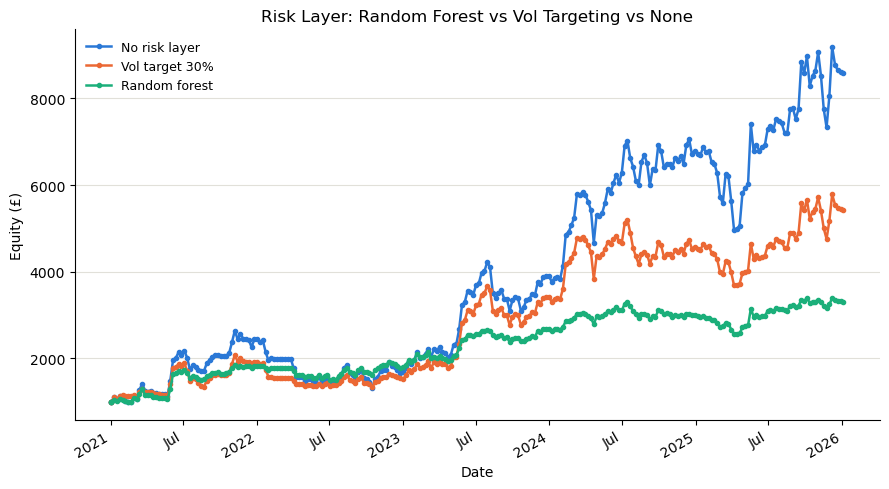

In [21]:
rows = []
for year in WF_YEARS:
    s, e = f"{year}-01-01", f"{year}-12-31"
    _, m_none = evaluate_exposure("none", None, s, e)
    _, m_vt   = evaluate_exposure("vt",   exposure_voltarget, s, e)
    _, m_rf   = evaluate_exposure("rf",   exposure_rf, s, e)
    rows.append({
        "year": year,
        "ret_none": m_none["total_return"], "ret_vt": m_vt["total_return"], "ret_rf": m_rf["total_return"],
        "sharpe_none": m_none["sharpe"],    "sharpe_vt": m_vt["sharpe"],   "sharpe_rf": m_rf["sharpe"],
        "dd_none": m_none["max_drawdown"],  "dd_vt": m_vt["max_drawdown"], "dd_rf": m_rf["max_drawdown"],
    })

wf = pd.DataFrame(rows).set_index("year")
print("Per-year, out-of-sample for the model:")
print(wf.to_string(float_format=lambda x: f"{x:,.3f}"))

print("\nFolds won (vs no risk layer):")
for name in ["vt", "rf"]:
    sh = (wf[f"sharpe_{name}"] > wf["sharpe_none"]).sum()
    dd = (wf[f"dd_{name}"] > wf["dd_none"]).sum()      # less negative == shallower drawdown
    both = ((wf[f"sharpe_{name}"] > wf["sharpe_none"]) & (wf[f"dd_{name}"] > wf["dd_none"])).sum()
    label = "Vol targeting" if name == "vt" else "Random forest"
    print(f"  {label:<15} better Sharpe {sh}/{len(wf)}   shallower drawdown {dd}/{len(wf)}   BOTH {both}/{len(wf)}")

# whole-span compounded view
span_s, span_e = f"{WF_YEARS[0]}-01-01", f"{WF_YEARS[-1]}-12-31"
span_curves, span_rows = {}, []
for label, exp in [("No risk layer", None), (f"Vol target {VOL_TARGET:.0%}", exposure_voltarget), ("Random forest", exposure_rf)]:
    c, m = evaluate_exposure(label, exp, span_s, span_e)
    span_curves[label] = c
    span_rows.append(m)
span_results = pd.DataFrame(span_rows).set_index("variant")
print(f"\nCompounded across {span_s}..{span_e}:")
print(span_results.to_string(float_format=lambda x: f"{x:,.3f}"))

plot_equity_curves(span_curves, "Risk Layer: Random Forest vs Vol Targeting vs None")
write_trades_sheet("Risk Layer (WF)", span_curves)


## 22. The Null Test: Does Timing Beat Simply Holding Less? ##

A risk layer that halves your drawdown has achieved nothing if it did so purely by holding half as
much stock — because you can hold half as much stock for free, with no model, no features and no
refitting.

So each schedule is compared against a **constant-exposure null set to that schedule's own average
exposure**. Same average capital at risk, all timing removed. If the dynamic version cannot beat
its own flat-line twin, its decisions carry no information and only its *size* was ever doing work.

This is the same null that dissolved the crypto watchlist, the ON Semi "edge" and the original
"Best Tuned" config. It applies to machine learning exactly as it applied to them.

In [22]:
null_rows, null_curves = [], {}
span_s, span_e = f"{WF_YEARS[0]}-01-01", f"{WF_YEARS[-1]}-12-31"

schedules = {
    f"Vol target {VOL_TARGET:.0%}": exposure_voltarget,
    "Random forest": exposure_rf,
}

_, m_unscaled = evaluate_exposure("No risk layer (100%)", None, span_s, span_e)
null_rows.append(m_unscaled)

for label, sched in schedules.items():
    avg = float(sched.reindex(pd.date_range(span_s, span_e)).dropna().mean())
    flat = pd.Series(avg, index=sched.index)

    c_dyn, m_dyn = evaluate_exposure(label, sched, span_s, span_e)
    c_flt, m_flt = evaluate_exposure(f"  -> CONSTANT {avg:.0%} null", flat, span_s, span_e)
    null_curves[label] = c_dyn
    null_rows += [m_dyn, m_flt]

null_results = pd.DataFrame(null_rows).set_index("variant")
print(f"Compounded {span_s}..{span_e} — each schedule against its own flat-line twin:")
print(null_results.to_string(float_format=lambda x: f"{x:,.3f}"))

print("\nPer-year verdict (dynamic vs its matched constant):")
for label, sched in schedules.items():
    avg = float(sched.reindex(pd.date_range(span_s, span_e)).dropna().mean())
    flat = pd.Series(avg, index=sched.index)
    wins = {"sharpe": 0, "dd": 0, "ret": 0}
    for y in WF_YEARS:
        s, e = f"{y}-01-01", f"{y}-12-31"
        _, a = evaluate_exposure("d", sched, s, e)
        _, b = evaluate_exposure("c", flat, s, e)
        wins["sharpe"] += a["sharpe"] > b["sharpe"]
        wins["dd"] += a["max_drawdown"] > b["max_drawdown"]      # less negative = shallower
        wins["ret"] += a["total_return"] > b["total_return"]
    n = len(WF_YEARS)
    print(f"  {label:<18} beats its null — Sharpe {wins['sharpe']}/{n}, "
          f"drawdown {wins['dd']}/{n}, return {wins['ret']}/{n}")

print("\nRead this as: anything at or near half the folds is a coin flip, i.e. no timing skill.")


Compounded 2021-01-01..2025-12-31 — each schedule against its own flat-line twin:
                        total_return  cagr  sharpe  max_drawdown  pct_up_days  turnover
variant                                                                                
No risk layer (100%)           7.576 0.540   1.019        -0.502        0.483       878
Vol target 30%                 4.425 0.404   0.955        -0.363        0.477      1045
  -> CONSTANT 80% null         5.233 0.444   1.006        -0.414        0.482       892
Random forest                  2.308 0.272   0.909        -0.240        0.480      1245
  -> CONSTANT 48% null         2.346 0.274   0.943        -0.264        0.482       900

Per-year verdict (dynamic vs its matched constant):


  Vol target 30%     beats its null — Sharpe 1/5, drawdown 2/5, return 2/5


  Random forest      beats its null — Sharpe 2/5, drawdown 3/5, return 2/5

Read this as: anything at or near half the folds is a coin flip, i.e. no timing skill.


## 23. Risk Attribution & Statistical Significance ##

The frozen test says +19% against the S&P's +13%. This section asks whether that number means
anything, in the three ways a fund would ask it:

1. **Is it alpha, or just beta?** A levered index position also beats the index.
2. **Is it alpha, or a known factor?** Small-cap and growth tilts are cheap to buy; nobody pays
   for them.
3. **Is it distinguishable from luck?** A Sharpe estimated over eight months has an enormous
   standard error, and the honest answer may be that the data simply cannot tell.

Factors use liquid ETF proxies rather than the Ken French series, which lags by a month or two and
does not yet cover the test window: `MKT = SPY`, `SMB = IWM − SPY`, `HML = IVE − IVW`,
`MOM = MTUM − SPY`. Coarser than the real thing, but enough to see whether anything survives.

In [23]:
FACTOR_ETFS = ["SPY", "IWM", "IVE", "IVW", "MTUM"]


def ols_with_tstats(y, X, names):
    """Plain OLS with t-statistics -- avoids a statsmodels dependency for four columns."""
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    resid = y - X @ beta
    dof = len(y) - X.shape[1]
    s2 = (resid @ resid) / dof
    se = np.sqrt(np.diag(np.linalg.inv(X.T @ X)) * s2)
    r2 = 1 - (resid @ resid) / (((y - y.mean()) ** 2).sum())
    return pd.DataFrame({"coef": beta, "t_stat": beta / se}, index=names), r2


def sharpe_standard_error(sharpe, years):
    """Lo (2002): SE(SR) ~ sqrt((1 + SR^2/2) / T) for iid returns, T measured in years.

    The point of this is that a Sharpe ratio is an ESTIMATE. Over a short window its standard
    error is large enough that a flattering point estimate carries almost no information.
    """
    return np.sqrt((1 + 0.5 * sharpe ** 2) / years)


# ---- the curve under examination: the frozen config, on the frozen window --------------------
attr_curve = run_backtest(data, FROZEN_PARAMS, INITIAL_CAPITAL, TRANSACTION_COST_PCT,
                          sim_start=TEST_START, sim_end=TEST_END)
attr_metrics = compute_metrics(attr_curve)
strategy_rets = attr_curve["equity"].pct_change().dropna()
rf_daily = RISK_FREE_RATE / 252

# ---- 1. beta and factor loadings -------------------------------------------------------------
factor_px = load_backtest_data(FACTOR_ETFS, TEST_START, TEST_END)
fr = {t: df["Close"].pct_change() for t, df in factor_px.items()}
factors = pd.DataFrame({
    "MKT": fr["SPY"],
    "SMB": fr["IWM"] - fr["SPY"],
    "HML": fr["IVE"] - fr["IVW"],
    "MOM": fr["MTUM"] - fr["SPY"],
}).dropna()

reg = pd.concat([strategy_rets.rename("y"), factors], axis=1).dropna()
excess = (reg["y"] - rf_daily).values

capm_X = np.column_stack([np.ones(len(reg)), (reg["MKT"] - rf_daily).values])
capm, capm_r2 = ols_with_tstats(excess, capm_X, ["alpha", "MKT"])

ff_X = np.column_stack([np.ones(len(reg)), (reg["MKT"] - rf_daily).values,
                        reg["SMB"].values, reg["HML"].values, reg["MOM"].values])
ff, ff_r2 = ols_with_tstats(excess, ff_X, ["alpha", "MKT", "SMB", "HML", "MOM"])

for frame in (capm, ff):
    frame.loc["alpha", "coef"] *= 252          # annualise the intercept only

print(f"Factor attribution on the frozen window ({TEST_START} to {TEST_END}, n={len(reg)} days)")
print(f"\nCAPM  (R^2 = {capm_r2:.2f}):")
print(capm.to_string(float_format=lambda x: f"{x:+.3f}"))
print(f"\nFour-factor  (R^2 = {ff_r2:.2f}):")
print(ff.to_string(float_format=lambda x: f"{x:+.3f}"))
print("\n  alpha is annualised; every other coefficient is a loading.")
print("  |t| < 2 means the coefficient is not distinguishable from zero on this sample.")

# ---- 2. is the Sharpe distinguishable from zero? ---------------------------------------------
years = (len(attr_curve) - 1) / 252
sr = attr_metrics["sharpe"]
se = sharpe_standard_error(sr, years)
print(f"\nSharpe reliability:")
print(f"  SR = {sr:.2f} over {years:.2f} years -> standard error {se:.2f}")
print(f"  95% confidence interval [{sr - 1.96 * se:+.2f}, {sr + 1.96 * se:+.2f}]")
print(f"  years of data needed to pin SR to +/-0.25: {(1 + 0.5 * sr ** 2) / 0.25 ** 2:.0f}")

# ---- 3. turnover and cost sensitivity --------------------------------------------------------
trades = pd.DataFrame(attr_curve.attrs["trades"])
notional = (trades["quantity"] * trades["price"]).sum()
avg_equity = attr_curve["equity"].mean()
print(f"\nTurnover:")
print(f"  {len(trades)} trades, £{notional:,.0f} gross notional on £{avg_equity:,.0f} average equity")
print(f"  annualised two-way turnover {notional / avg_equity / years:.1f}x of capital per year")

rows = []
for extra in [0.0, 0.0010, 0.0020, 0.0050]:
    m = compute_metrics(run_backtest(data, FROZEN_PARAMS, INITIAL_CAPITAL,
                                     TRANSACTION_COST_PCT + extra,
                                     sim_start=TEST_START, sim_end=TEST_END))
    rows.append({"extra_cost": f"+{extra * 1e4:.0f} bps/trade", "total_return": m["total_return"],
                 "sharpe": m["sharpe"], "trades": m["turnover"]})
cost_sensitivity = pd.DataFrame(rows).set_index("extra_cost")
print(f"\nCost sensitivity (on top of the {TRANSACTION_COST_PCT:.2%} FX fee already modelled):")
print(cost_sensitivity.to_string(float_format=lambda x: f"{x:,.3f}"))

# ---- verdict ---------------------------------------------------------------------------------
alpha_t = ff.loc["alpha", "t_stat"]
print("\n" + "=" * 78)
print(f"Four-factor alpha {ff.loc['alpha', 'coef']:+.2%}/yr at t = {alpha_t:+.2f}"
      f" -> {'NOT distinguishable from zero' if abs(alpha_t) < 2 else 'statistically significant'}.")
print(f"CAPM beta {capm.loc['MKT', 'coef']:.2f}: the excess return is "
      f"{'largely leverage to the market, not skill' if capm.loc['MKT', 'coef'] > 1.3 else 'not simply beta'}.")
print(f"Sharpe CI spans {sr - 1.96 * se:+.2f} to {sr + 1.96 * se:+.2f}"
      f"{' -- includes zero, so the window cannot support any claim of edge.' if sr - 1.96 * se < 0 else '.'}")
print("=" * 78)


Factor attribution on the frozen window (2026-01-01 to 2026-09-01, n=165 days)

CAPM  (R^2 = 0.33):
        coef  t_stat
alpha +0.029  +0.058
MKT   +2.059  +8.942

Four-factor  (R^2 = 0.42):
        coef  t_stat
alpha +0.048  +0.103
MKT   +1.058  +3.320
SMB   +1.063  +3.205
HML   -0.871  -2.827
MOM   +0.141  +0.746

  alpha is annualised; every other coefficient is a loading.
  |t| < 2 means the coefficient is not distinguishable from zero on this sample.

Sharpe reliability:
  SR = 0.71 over 0.66 years -> standard error 1.38
  95% confidence interval [-1.99, +3.41]
  years of data needed to pin SR to +/-0.25: 20

Turnover:
  132 trades, £23,769 gross notional on £1,022 average equity
  annualised two-way turnover 35.3x of capital per year

Cost sensitivity (on top of the 0.15% FX fee already modelled):
               total_return  sharpe  trades
extra_cost                                 
+0 bps/trade          0.191   0.707     132
+10 bps/trade         0.164   0.633     135
+20 bps/t

## 24. Combined Trade Log (Data Wrangler) ##

In [24]:
# Reads back every sheet already written to Backtest_trade_log.xlsx and combines them into one table,
# tagged by which experiment each row came from. Ending on a bare DataFrame (no print) is what lets
# VS Code's Data Wrangler attach to this cell's output -- from there you can export to Excel yourself.
all_sheets = pd.read_excel(BACKTEST_TRADE_LOG_PATH, sheet_name=None)
combined_trades = pd.concat(
    [df.assign(experiment=sheet_name) for sheet_name, df in all_sheets.items()],
    ignore_index=True,
)
combined_trades


,variant,date,ticker,side,quantity,price,equity,experiment
0,Momentum (baseline),2019-01-07,TSLA,BUY,22.357146,22.330667,999.250000,Strategy vs Benchmark (Train)
1,Momentum (baseline),2019-01-07,INTC,BUY,12.228169,40.827862,998.500000,Strategy vs Benchmark (Train)
2,Momentum (baseline),2019-01-14,INTC,SELL (rebalance),12.228169,41.611027,1006.478742,Strategy vs Benchmark (Train)
3,Momentum (baseline),2019-01-14,TSLA,SELL (trim),7.308122,22.293333,1006.234359,Strategy vs Benchmark (Train)
4,Momentum (baseline),2019-01-14,SMCI,BUY,218.376575,1.534000,1005.731119,Strategy vs Benchmark (Train)
...,...,...,...,...,...,...,...,...
24176,Random forest,2025-12-29,AAL,BUY,7.824471,15.140000,3313.460394,Risk Layer (WF)
24177,Random forest,2025-12-29,PATH,BUY,4.869951,16.850000,3313.337122,Risk Layer (WF)
24178,Random forest,2025-12-31,INTC,SELL (de-risk),2.228851,36.900002,3308.425275,Risk Layer (WF)
24179,Random forest,2025-12-31,PATH,SELL (de-risk),4.851888,16.389999,3308.305991,Risk Layer (WF)
